# code_101 · Bottlenecks, denoising and small vibration patterns

**Book:** section 20.4. A self-contained representation laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_20_GUIDE.md), [run evidence](../CHAPTER_20_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_101).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2101;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2101


<a id="bottleneck"></a>
 ## Fit compression to admitted vibration windows
 Generate 32-sample windows with two dominant orthonormal sine/cosine modes, a small independent binary pattern and measurement noise. Train/development/final sizes are 300/80/200. All centering uses training inputs. Linear and nonlinear two-coordinate autoencoders use 800 full-batch Adam updates at rate 0.01, weight decay 0.0001. Denoising adds fresh Gaussian noise of standard deviation 0.08 to the observed training measurement and predicts that original measurement, not the hidden noiseless generator. Development is diagnostic; no model or epoch is selected with final labels.


,method,development_MSE,final_measurement_MSE,corrupted_input_MSE,noiseless_oracle_MSE,pattern_retained_fraction
0,Identity,0.000000,0.000000,0.006418,0.000400,1.000000
1,PCA,0.000534,0.000554,0.000996,0.000206,0.003008
2,Linear AE,0.000537,0.000556,0.001010,0.000208,0.005497
3,Nonlinear AE,0.001978,0.001232,0.002033,0.000866,0.149030
4,Denoising AE,0.001915,0.001214,0.001670,0.000855,0.048284


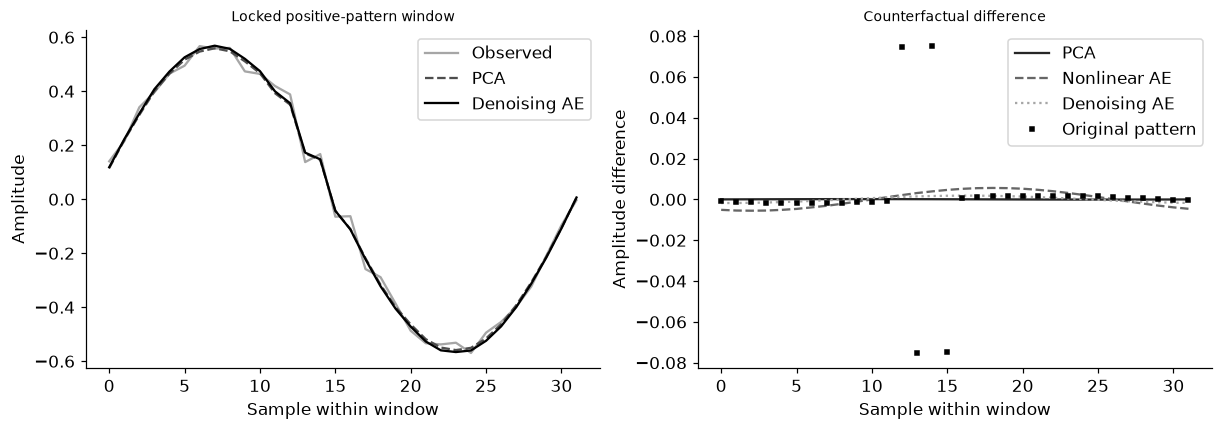

In [2]:
import torch
from torch import nn
from sklearn.decomposition import PCA
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True);VERSIONS['torch']=torch.__version__
phase=np.arange(32)*2*np.pi/32;basis=np.column_stack([np.sin(phase),np.cos(phase)]);basis=np.linalg.qr(basis)[0]
pattern=np.zeros(32);pattern[12:16]=[1,-1,1,-1];pattern-=basis@(basis.T@pattern);pattern/=np.linalg.norm(pattern)
assert np.max(np.abs(basis.T@pattern))<1e-12
def sample(n):
    amplitudes=rng.normal(0,1.5,(n,2));y=rng.integers(0,2,n);clean=amplitudes@basis.T+.15*y[:,None]*pattern
    return clean+rng.normal(0,.02,(n,32)),clean,y
train,train_clean,ytrain=sample(300);dev,dev_clean,ydev=sample(80);final,final_clean,yfinal=sample(200)
center=train.mean(0);x=torch.tensor(train-center);pca=PCA(2,svd_solver='full').fit(train)
class AE(nn.Module):
    def __init__(self,linear=False):
        super().__init__();self.encoder=nn.Linear(32,2) if linear else nn.Sequential(nn.Linear(32,8),nn.Tanh(),nn.Linear(8,2),nn.Tanh());self.decoder=nn.Linear(2,32) if linear else nn.Sequential(nn.Linear(2,8),nn.Tanh(),nn.Linear(8,32))
    def forward(self,z):return self.decoder(self.encoder(z))
models={};curves={}
for index,(name,linear,noise) in enumerate([('Linear AE',True,0.),('Nonlinear AE',False,0.),('Denoising AE',False,.08)]):
    torch.manual_seed(SEED+index);model=AE(linear);optimizer=torch.optim.Adam(model.parameters(),lr=.01,weight_decay=1e-4);losses=[]
    for step in range(800):
        optimizer.zero_grad();noisy=x+noise*torch.randn_like(x);loss=torch.mean((model(noisy)-x)**2);loss.backward()
        assert all(torch.isfinite(p.grad).all() for p in model.parameters());optimizer.step()
        if step%20==0:losses.append([step,float(loss.detach())])
    model.eval();models[name]=model;curves[name]=losses
def reconstruct(name,values):
    if name=='PCA':return pca.inverse_transform(pca.transform(values))
    if name=='Identity':return values.copy()
    with torch.no_grad():return models[name](torch.tensor(values-center)).numpy()+center
corrupted=final+rng.normal(0,.08,final.shape);pair=np.vstack([np.zeros(32),.15*pattern]);rows=[]
for name in ['Identity','PCA',*models]:
    estimate=reconstruct(name,final);paired=reconstruct(name,pair)
    rows.append({'method':name,'development_MSE':float(np.mean((reconstruct(name,dev)-dev)**2)),'final_measurement_MSE':float(np.mean((estimate-final)**2)),'corrupted_input_MSE':float(np.mean((reconstruct(name,corrupted)-final)**2)),'noiseless_oracle_MSE':float(np.mean((estimate-final_clean)**2)),'pattern_retained_fraction':float(np.linalg.norm(paired[1]-paired[0])/.15)})
assert rows[0]['final_measurement_MSE']==0
# This is the closed-form diagonal Gaussian KL, not a trained VAE.
def gaussian_kl(mu,logvar):return .5*np.sum(mu*mu+np.exp(logvar)-1-logvar)
assert gaussian_kl(np.zeros(2),np.zeros(2))==0 and gaussian_kl(np.ones(2),np.zeros(2))>0
RESULTS.update(metrics=rows,training_steps=800,gaussian_KL_shift_example=float(gaussian_kl(np.ones(2),np.zeros(2))),parameter_counts={k:sum(p.numel() for p in m.parameters()) for k,m in models.items()},split_sizes=[300,80,200])
display(pd.DataFrame(rows))
fig,axes=plt.subplots(1,2,figsize=(11,3.8));case=int(np.flatnonzero(yfinal)[0])
axes[0].plot(final[case],color='.65',label='Observed');axes[0].plot(reconstruct('PCA',final)[case],'--',color='.3',label='PCA');axes[0].plot(reconstruct('Denoising AE',final)[case],color='black',label='Denoising AE');axes[0].set(title='Locked positive-pattern window',xlabel='Sample within window',ylabel='Amplitude');axes[0].legend()
for index,name in enumerate(['PCA','Nonlinear AE','Denoising AE']):
    paired=reconstruct(name,pair);axes[1].plot(paired[1]-paired[0],linestyle=['-','--',':'][index],color=str(.15+index*.25),label=name)
axes[1].plot(.15*pattern,'s',markersize=3,color='black',label='Original pattern');axes[1].set(title='Counterfactual difference',xlabel='Sample within window',ylabel='Amplitude difference');axes[1].legend();plt.show()


<a id="limits"></a>
 ## What the losses can certify
 Identity reproduces a measurement exactly, including its noise, and uses all 32 coordinates. It is not a compressed representation. The oracle noiseless loss is only available because this teaching generator is known; it is not available for field deployment. Fixed training steps and finite gradients do not certify a global optimum. The analytic Gaussian KL connects a regularized latent distribution to Chapter 27; no variational encoder, decoder likelihood or generative model is trained here. This experiment tests CPU reproducibility within the pinned environment, not across releases or hardware.


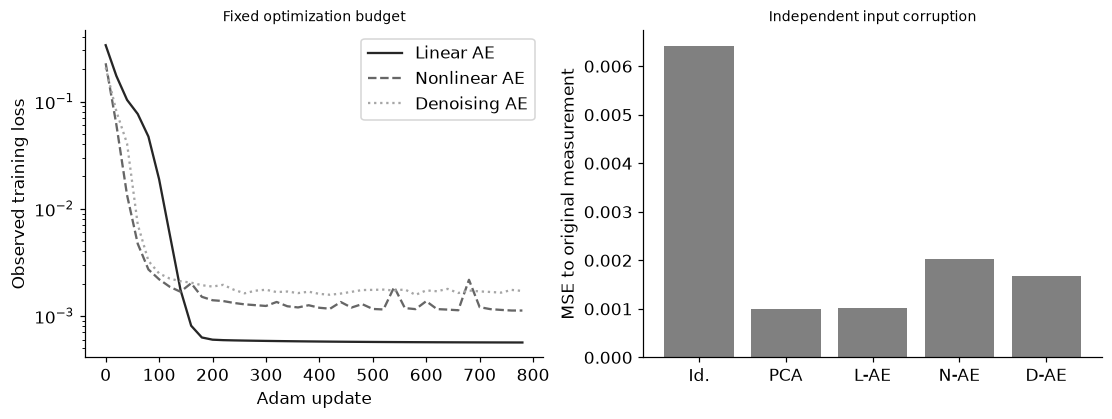

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,3.7))
for index,(name,history) in enumerate(curves.items()):
    values=np.array(history);axes[0].plot(values[:,0],values[:,1],linestyle=['-','--',':'][index],color=str(.15+index*.25),label=name)
axes[0].set(yscale='log',xlabel='Adam update',ylabel='Observed training loss',title='Fixed optimization budget');axes[0].legend()
xx=np.arange(len(rows));axes[1].bar(xx,[r['corrupted_input_MSE'] for r in rows],color='.5');axes[1].set(xticks=xx,xticklabels=['Id.','PCA','L-AE','N-AE','D-AE'],ylabel='MSE to original measurement',title='Independent input corruption');plt.show()
assert all(np.isfinite(r['corrupted_input_MSE']) for r in rows)


In [4]:
summary={'example_id':'code_101','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual CPU autoencoder training', 'denoising measurement targets', 'bottleneck versus identity', 'analytic Gaussian KL connection'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual CPU autoencoder training", "denoising measurement targets", "bottleneck versus identity", "analytic Gaussian KL connection"], "elapsed_seconds": 1.606, "example_id": "code_101", "hardware": "Darwin arm64 CPU", "results": {"gaussian_KL_shift_example": 1.0, "metrics": [{"corrupted_input_MSE": 0.006417549669590323, "development_MSE": 0.0, "final_measurement_MSE": 0.0, "method": "Identity", "noiseless_oracle_MSE": 0.00039961365989749244, "pattern_retained_fraction": 1.0}, {"corrupted_input_MSE": 0.0009955537459705793, "development_MSE": 0.0005342337001933694, "final_measurement_MSE": 0.0005536244545914369, "method": "PCA", "noiseless_oracle_MSE": 0.00020602991637269508, "pattern_retained_fraction": 0.0030082680073932216}, {"corrupted_input_MSE": 0.0010097826815586954, "development_MSE": 0.0005365498864991363, "final_measurement_MSE": 0.0005563961224612249, "method": "Linear AE", "noiseless_oracle_MSE": 0.00020821293439969604, "patte